# Minggu 4: Praktikum 2 - DBSCAN Clustering


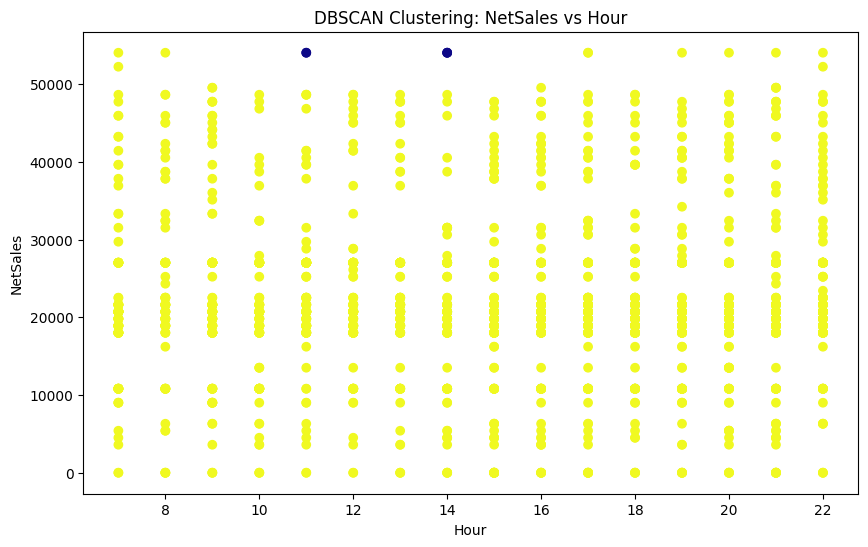

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

# Load & Sampling (DBSCAN lambat untuk data sangat besar)
df = pd.read_csv('../datasetPBL/Transactions.csv').sample(2000, random_state=42)
df['Hour'] = pd.to_datetime(df['Time'], format='%H:%M:%S').dt.hour

X = df[['NetSales', 'Hour']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# DBSCAN
dbscan = DBSCAN(eps=0.5, min_samples=5)
df['Cluster_DB'] = dbscan.fit_predict(X_scaled)

plt.figure(figsize=(10,6))
plt.scatter(df['Hour'], df['NetSales'], c=df['Cluster_DB'], cmap='plasma')
plt.title('DBSCAN Clustering: NetSales vs Hour')
plt.xlabel('Hour')
plt.ylabel('NetSales')
plt.show()